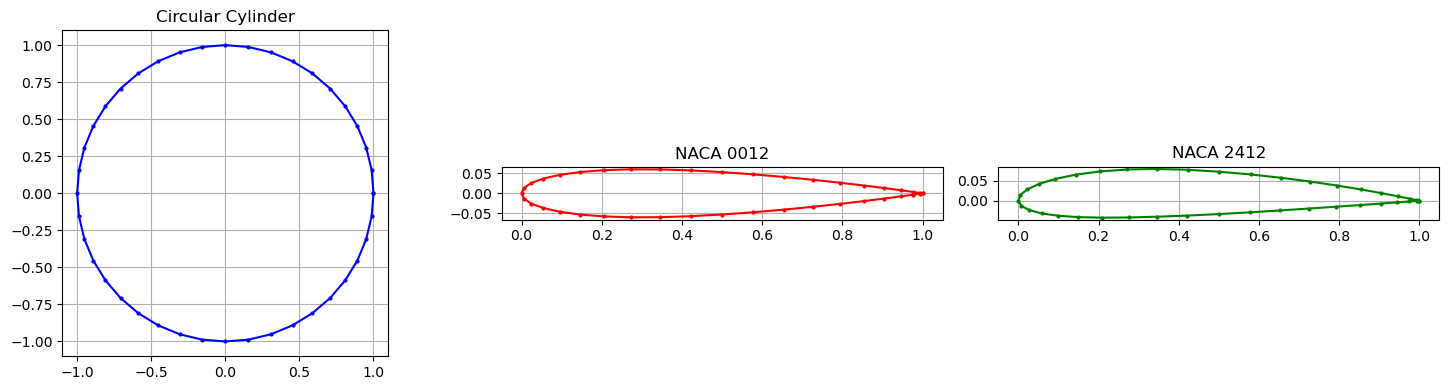

Geometry generation completed
--------------------------------
Number of panels: 40
Number of control points: 40
First panel length: 0.0062
First panel angle: 184.4256
First beta angle: 269.4256


In [1]:

# Vortex Panel Method - Geometry Generation

import numpy as np
import matplotlib.pyplot as plt


# 1. Numerical output formatting


def fmt(value, digits=4):
    value = float(value)

    if abs(value) < 0.5 * 10**(-digits):
        return "0"

    return f"{value:.{digits}f}".rstrip("0").rstrip(".")



# 2. Calculate panel geometry


def panel_geometry(XB, YB):

    dX = np.diff(XB)
    dY = np.diff(YB)

    # Panel length
    S = np.hypot(dX, dY)

    # Panel orientation angle
    phi = np.mod(np.arctan2(dY, dX), 2*np.pi)

    # Control point coordinates
    XC = 0.5 * (XB[:-1] + XB[1:])
    YC = 0.5 * (YB[:-1] + YB[1:])

    return XC, YC, S, phi



# 3. Calculate beta angle


def beta_angle(phi, alpha):

    beta = phi + np.pi/2 - alpha

    return beta


# 4. Generate circular cylinder coordinates


def cylinder_boundary_points(N, R=1.0):

    theta = np.linspace(0, -2*np.pi, N+1)

    XB = R * np.cos(theta)
    YB = R * np.sin(theta)

    return XB, YB



# 5. Generate NACA four-digit airfoil coordinates


def naca4_boundary_points(code, N, spacing='cosine'):

    if len(code) != 4 or not code.isdigit():
        raise ValueError("Enter a valid four-digit NACA code")

    if N < 4 or N % 2 != 0:
        raise ValueError("N must be an even number of at least 4")

    # Read NACA parameters
    m = int(code[0]) / 100
    p = int(code[1]) / 10
    t = int(code[2:]) / 100

    # Chordwise coordinate distribution
    n_side = N // 2

    if spacing == 'cosine':

        theta = np.linspace(0, np.pi, n_side+1)
        x = 0.5 * (1 - np.cos(theta))

    elif spacing == 'uniform':

        x = np.linspace(0, 1, n_side+1)

    else:

        raise ValueError("Spacing must be cosine or uniform")

    # Thickness distribution
    yt = 5*t*(
        0.2969*np.sqrt(x)
        - 0.1260*x
        - 0.3516*x**2
        + 0.2843*x**3
        - 0.1036*x**4
    )

    # Mean camber line
    yc = np.zeros_like(x)
    dyc_dx = np.zeros_like(x)

    if m != 0:

        for i in range(len(x)):

            if x[i] < p:

                yc[i] = (m/p**2) * (
                    2*p*x[i] - x[i]**2
                )

                dyc_dx[i] = (
                    2*m/p**2
                ) * (p-x[i])

            else:

                yc[i] = (m/(1-p)**2) * (
                    (1-2*p) + 2*p*x[i] - x[i]**2
                )

                dyc_dx[i] = (
                    2*m/(1-p)**2
                ) * (p-x[i])

    # Camber line angle
    theta_c = np.arctan(dyc_dx)

    # Upper surface coordinates
    xu = x - yt*np.sin(theta_c)
    yu = yc + yt*np.cos(theta_c)

    # Lower surface coordinates
    xl = x + yt*np.sin(theta_c)
    yl = yc - yt*np.cos(theta_c)

    # Arrange coordinates clockwise:
    # Trailing edge -> Lower surface -> Leading edge
    # -> Upper surface -> Trailing edge

    XB = np.concatenate((xl[::-1], xu[1:]))
    YB = np.concatenate((yl[::-1], yu[1:]))

    return XB, YB



# 6. Test the geometry functions


N = 40

# Cylinder
XB_cyl, YB_cyl = cylinder_boundary_points(N)

# NACA 0012
XB_0012, YB_0012 = naca4_boundary_points(
    '0012', N, spacing='cosine'
)

# NACA 2412
XB_2412, YB_2412 = naca4_boundary_points(
    '2412', N, spacing='cosine'
)



# 7. Plot generated geometries


fig, ax = plt.subplots(1, 3, figsize=(15, 4))

ax[0].plot(XB_cyl, YB_cyl, 'b-o', markersize=2)
ax[0].set_title('Circular Cylinder')
ax[0].set_aspect('equal')
ax[0].grid()

ax[1].plot(XB_0012, YB_0012, 'r-o', markersize=2)
ax[1].set_title('NACA 0012')
ax[1].set_aspect('equal')
ax[1].grid()

ax[2].plot(XB_2412, YB_2412, 'g-o', markersize=2)
ax[2].set_title('NACA 2412')
ax[2].set_aspect('equal')
ax[2].grid()

plt.tight_layout()
plt.show()



# 8. Check panel geometry


XC, YC, S, phi = panel_geometry(
    XB_2412, YB_2412
)

alpha = np.radians(5)

beta = beta_angle(phi, alpha)

print("Geometry generation completed")
print("--------------------------------")
print("Number of panels:", len(S))
print("Number of control points:", len(XC))
print("First panel length:", fmt(S[0]))
print("First panel angle:", fmt(np.degrees(phi[0])))
print("First beta angle:", fmt(np.degrees(beta[0])))


In [2]:

from numpy.polynomial.legendre import leggauss


def compute_JK(XB, YB, XC, YC, phi):

    N = len(XC)

    J = np.zeros((N, N))
    K = np.zeros((N, N))

    # Gauss-Legendre integration points
    points, weights = leggauss(40)

    S = np.hypot(np.diff(XB), np.diff(YB))

    for i in range(N):

        # Normal and tangential directions
        nx = -np.sin(phi[i])
        ny = np.cos(phi[i])

        tx = np.cos(phi[i])
        ty = np.sin(phi[i])

        for j in range(N):

            # Self-influence: principal value
            if i == j:
                continue

            dx = XB[j+1] - XB[j]
            dy = YB[j+1] - YB[j]
            Sj = S[j]

            # Integration points along panel j
            s = 0.5 * Sj * (points + 1)
            w = 0.5 * Sj * weights

            xq = XB[j] + s * dx / Sj
            yq = YB[j] + s * dy / Sj

            # Distance from the vortex element to control point i
            rx = XC[i] - xq
            ry = YC[i] - yq

            r2 = rx**2 + ry**2

            # Induced velocity due to a unit vortex element
            u = -ry / (2 * np.pi * r2)
            v = rx / (2 * np.pi * r2)

            u_ind = np.sum(w * u)
            v_ind = np.sum(w * v)

            # Resolve velocity into normal and tangential components
            J[i, j] = u_ind * nx + v_ind * ny
            K[i, j] = u_ind * tx + v_ind * ty

    return J, K


# Calculate influence coefficients for NACA 2412
XC, YC, S, phi = panel_geometry(XB_2412, YB_2412)

J, K = compute_JK(XB_2412, YB_2412, XC, YC, phi)

print("Constant-strength influence coefficients")
print("-----------------------------------------")
print("Number of panels:", len(S))
print("J matrix size:", J.shape)
print("K matrix size:", K.shape)
print("J[0, 1]:", fmt(J[0, 1]))
print("K[0, 1]:", fmt(K[0, 1]))


Constant-strength influence coefficients
-----------------------------------------
Number of panels: 40
J matrix size: (40, 40)
K matrix size: (40, 40)
J[0, 1]: -0.3085
K[0, 1]: -0.0001


Constant-strength vortex panel solution
----------------------------------------
Number of panels: 40
Angle of attack: 5 degrees
Lift coefficient: 0.8371
Minimum Cp: -5.2839
Maximum Cp: 0.9998
First vortex strength: 0.9112
Last vortex strength: -0.9112
Kutta condition: 0
Maximum normal velocity error: 0.0002


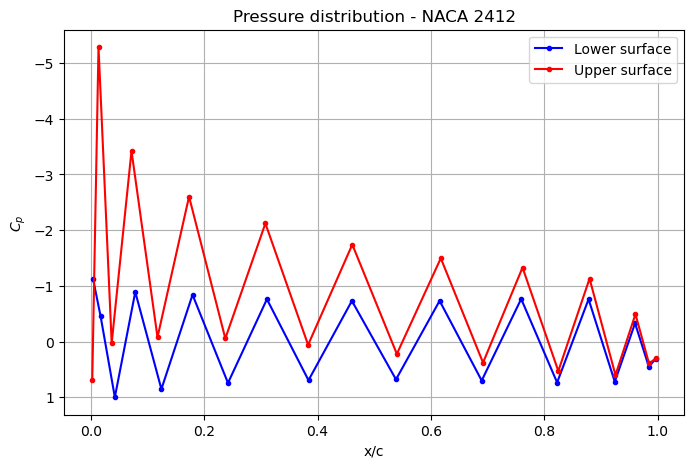

In [3]:

def vortex_panel_method_0(XB, YB, alpha, V_inf=1, chord=1):

    # Panel geometry
    XC, YC, S, phi = panel_geometry(XB, YB)
    N = len(S)

    # Influence coefficient matrices
    J = np.zeros((N, N))
    K = np.zeros((N, N))

    # Calculate the influence of each panel
    for i in range(N):

        nx = -np.sin(phi[i])
        ny = np.cos(phi[i])

        tx = np.cos(phi[i])
        ty = np.sin(phi[i])

        for j in range(N):

            if i == j:
                continue

            # Transform control point into local panel coordinates
            dx = XC[i] - XB[j]
            dy = YC[i] - YB[j]

            x = dx*np.cos(phi[j]) + dy*np.sin(phi[j])
            y = -dx*np.sin(phi[j]) + dy*np.cos(phi[j])

            Sj = S[j]

            # Analytical velocity induced by a constant vortex panel
            theta1 = np.arctan2(-x, abs(y))
            theta2 = np.arctan2(Sj-x, abs(y))

            u_local = -np.sign(y)*(theta2-theta1)/(2*np.pi)

            r1 = x**2 + y**2
            r2 = (x-Sj)**2 + y**2

            v_local = np.log(r1/r2)/(4*np.pi)

            # Transform velocity into global coordinates
            u = u_local*np.cos(phi[j]) - v_local*np.sin(phi[j])
            v = u_local*np.sin(phi[j]) + v_local*np.cos(phi[j])

            # Normal and tangential influence coefficients
            J[i, j] = u*nx + v*ny
            K[i, j] = u*tx + v*ty

    # Freestream velocity components
    Vx = V_inf*np.cos(alpha)
    Vy = V_inf*np.sin(alpha)

    # Outward normal components
    nx = -np.sin(phi)
    ny = np.cos(phi)

    # No-penetration boundary condition
    RHS = -(Vx*nx + Vy*ny)

    # Apply the Kutta condition
    # gamma[0] + gamma[-1] = 0

    A = np.zeros((N, N-1))

    A[:, 0] = J[:, 0] - J[:, -1]
    A[:, 1:] = J[:, 1:-1]

    # Solve for the vortex strengths
    gamma_reduced, residuals, rank, singular_values = np.linalg.lstsq(
        A, RHS, rcond=None
    )

    # Recover all panel strengths
    gamma = np.zeros(N)

    gamma[0] = gamma_reduced[0]
    gamma[1:-1] = gamma_reduced[1:]
    gamma[-1] = -gamma[0]

    # Freestream tangential velocity
    Vt_inf = Vx*np.cos(phi) + Vy*np.sin(phi)

    # Tangential velocity on the outer surface
    Vt = Vt_inf + K @ gamma - 0.5*gamma

    # Pressure coefficient
    Cp = 1 - (Vt/V_inf)**2

    # Check the boundary condition
    normal_velocity = Vx*nx + Vy*ny + J @ gamma

    max_normal_error = np.max(np.abs(normal_velocity))

    # Lift coefficient from pressure integration
    Cl = -np.sum(Cp*ny*S)/chord

    return gamma, Vt, Cp, Cl, max_normal_error


# NACA 2412 at 5 degrees angle of attack
alpha = np.radians(5)

gamma, Vt, Cp, Cl, normal_error = vortex_panel_method_0(
    XB_2412,
    YB_2412,
    alpha,
    V_inf=1,
    chord=1
)

print("Constant-strength vortex panel solution")
print("----------------------------------------")
print("Number of panels:", len(gamma))
print("Angle of attack:", fmt(np.degrees(alpha)), "degrees")
print("Lift coefficient:", fmt(Cl))
print("Minimum Cp:", fmt(np.min(Cp)))
print("Maximum Cp:", fmt(np.max(Cp)))
print("First vortex strength:", fmt(gamma[0]))
print("Last vortex strength:", fmt(gamma[-1]))
print("Kutta condition:", fmt(gamma[0] + gamma[-1]))
print("Maximum normal velocity error:", fmt(normal_error))


# Separate upper and lower surface pressure distributions
mid = len(Cp)//2

plt.figure(figsize=(8, 5))

plt.plot(
    XC[:mid], Cp[:mid],
    'bo-', markersize=3, label='Lower surface'
)

plt.plot(
    XC[mid:], Cp[mid:],
    'ro-', markersize=3, label='Upper surface'
)

plt.gca().invert_yaxis()
plt.xlabel("x/c")
plt.ylabel("$C_p$")
plt.title("Pressure distribution - NACA 2412")
plt.legend()
plt.grid()
plt.show()


In [4]:

from numpy.polynomial.legendre import leggauss


def compute_JK_linear(XB, YB, XC, YC, phi):

    N = len(XC)

    # N panels have N+1 nodal vortex strengths
    J_linear = np.zeros((N, N+1))
    K_linear = np.zeros((N, N+1))

    points, weights = leggauss(40)

    S = np.hypot(np.diff(XB), np.diff(YB))

    for i in range(N):

        # Normal and tangential directions at control point i
        nx = -np.sin(phi[i])
        ny = np.cos(phi[i])

        tx = np.cos(phi[i])
        ty = np.sin(phi[i])

        for j in range(N):

            # Self-panel principal-value contribution
            if i == j:
                continue

            dx = XB[j+1] - XB[j]
            dy = YB[j+1] - YB[j]
            Sj = S[j]

            # Gauss points along panel j
            s = 0.5 * Sj * (points + 1)
            w = 0.5 * Sj * weights

            xq = XB[j] + s * dx / Sj
            yq = YB[j] + s * dy / Sj

            rx = XC[i] - xq
            ry = YC[i] - yq

            r2 = rx**2 + ry**2

            # Velocity induced by a unit vortex element
            u = -ry / (2 * np.pi * r2)
            v = rx / (2 * np.pi * r2)

            # Linear shape functions
            N1 = 1 - s / Sj
            N2 = s / Sj

            # Contributions from the two endpoint strengths
            u1 = np.sum(w * N1 * u)
            v1 = np.sum(w * N1 * v)

            u2 = np.sum(w * N2 * u)
            v2 = np.sum(w * N2 * v)

            # Resolve into normal and tangential directions
            J_linear[i, j] += u1 * nx + v1 * ny
            K_linear[i, j] += u1 * tx + v1 * ty

            J_linear[i, j+1] += u2 * nx + v2 * ny
            K_linear[i, j+1] += u2 * tx + v2 * ty

    return J_linear, K_linear


# Test using NACA 2412
XC, YC, S, phi = panel_geometry(XB_2412, YB_2412)

J_linear, K_linear = compute_JK_linear(
    XB_2412, YB_2412, XC, YC, phi
)

print("Linear-strength influence coefficients")
print("---------------------------------------")
print("Number of panels:", len(S))
print("Number of nodal strengths:", len(S) + 1)
print("J matrix size:", J_linear.shape)
print("K matrix size:", K_linear.shape)
print("J[0, 1]:", fmt(J_linear[0, 1]))
print("K[0, 1]:", fmt(K_linear[0, 1]))


Linear-strength influence coefficients
---------------------------------------
Number of panels: 40
Number of nodal strengths: 41
J matrix size: (40, 41)
K matrix size: (40, 41)
J[0, 1]: -0.2012
K[0, 1]: -0.0001


Linear-strength vortex panel solution
--------------------------------------
Number of panels: 40
Number of nodal strengths: 41
Angle of attack: 5 degrees
Lift coefficient: 0.8376
Minimum Cp: -1.6637
Maximum Cp: 0.8892
First vortex strength: -0.0755
Last vortex strength: 0.0755
Kutta condition: 0
Maximum normal velocity error: 0


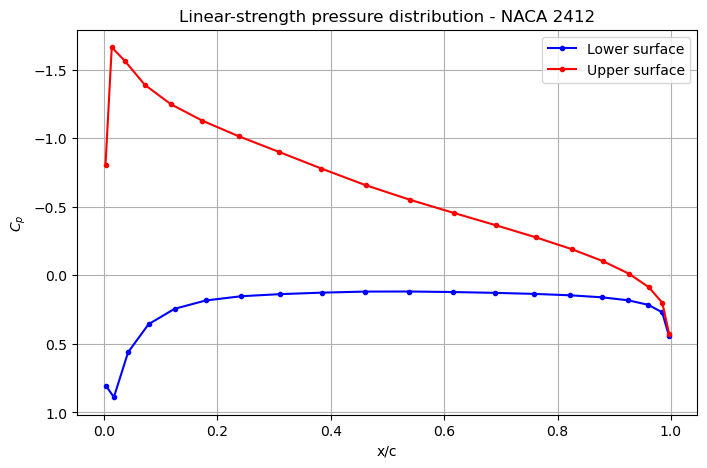

In [5]:

def vortex_panel_method_1(XB, YB, alpha, V_inf=1, chord=1):

    # Calculate panel geometry
    XC, YC, S, phi = panel_geometry(XB, YB)

    N = len(S)

    # Calculate linear influence coefficients
    J_linear, K_linear = compute_JK_linear(
        XB, YB, XC, YC, phi
    )

    # Self-panel principal-value correction
    for j in range(N):
        J_linear[j, j] += 1 / (2 * np.pi)
        J_linear[j, j+1] -= 1 / (2 * np.pi)

    # Freestream velocity components
    Vx = V_inf * np.cos(alpha)
    Vy = V_inf * np.sin(alpha)

    # Outward normal components
    nx = -np.sin(phi)
    ny = np.cos(phi)

    # No-penetration boundary condition
    RHS = -(Vx * nx + Vy * ny)

    # Add the Kutta condition
    A = np.zeros((N+1, N+1))
    b = np.zeros(N+1)

    A[:N, :] = J_linear
    b[:N] = RHS

    # Kutta condition at the trailing edge
    A[N, 0] = 1
    A[N, -1] = 1

    # Solve for nodal vortex strengths
    gamma = np.linalg.solve(A, b)

    # Freestream tangential velocity
    Vt_inf = Vx * np.cos(phi) + Vy * np.sin(phi)

    # Vortex strength at each panel midpoint
    gamma_mid = 0.5 * (gamma[:-1] + gamma[1:])

    # Tangential surface velocity
    Vt = Vt_inf + K_linear @ gamma - 0.5 * gamma_mid

    # Pressure coefficient
    Cp = 1 - (Vt / V_inf)**2

    # Lift coefficient from pressure integration
    Cl = -np.sum(Cp * ny * S) / chord

    # Check normal boundary condition
    normal_velocity = Vx * nx + Vy * ny + J_linear @ gamma

    max_normal_error = np.max(np.abs(normal_velocity))

    return gamma, Vt, Cp, Cl, max_normal_error


# Test using NACA 2412 at 5 degrees
alpha = np.radians(5)

gamma_linear, Vt_linear, Cp_linear, Cl_linear, normal_error = (
    vortex_panel_method_1(
        XB_2412,
        YB_2412,
        alpha,
        V_inf=1,
        chord=1
    )
)

print("Linear-strength vortex panel solution")
print("--------------------------------------")
print("Number of panels:", len(S))
print("Number of nodal strengths:", len(gamma_linear))
print("Angle of attack:", fmt(np.degrees(alpha)), "degrees")
print("Lift coefficient:", fmt(Cl_linear))
print("Minimum Cp:", fmt(np.min(Cp_linear)))
print("Maximum Cp:", fmt(np.max(Cp_linear)))
print("First vortex strength:", fmt(gamma_linear[0]))
print("Last vortex strength:", fmt(gamma_linear[-1]))
print("Kutta condition:", fmt(gamma_linear[0] + gamma_linear[-1]))
print("Maximum normal velocity error:", fmt(normal_error))


# Plot pressure coefficient on the airfoil
mid = len(Cp_linear) // 2

plt.figure(figsize=(8, 5))

plt.plot(
    XC[:mid], Cp_linear[:mid],
    'bo-', markersize=3, label='Lower surface'
)

plt.plot(
    XC[mid:], Cp_linear[mid:],
    'ro-', markersize=3, label='Upper surface'
)

plt.gca().invert_yaxis()
plt.xlabel("x/c")
plt.ylabel("$C_p$")
plt.title("Linear-strength pressure distribution - NACA 2412")
plt.legend()
plt.grid()
plt.show()


In [6]:

def cylinder_test_constant(N, alpha, V_inf=1):

    # Generate circular cylinder geometry
    XB, YB = cylinder_boundary_points(N, R=1)

    XC, YC, S, phi = panel_geometry(XB, YB)

    # Calculate influence coefficients
    J, K = compute_JK(XB, YB, XC, YC, phi)

    # Freestream velocity
    Vx = V_inf * np.cos(alpha)
    Vy = V_inf * np.sin(alpha)

    # Outward normal components
    nx = -np.sin(phi)
    ny = np.cos(phi)

    # No-penetration boundary condition
    RHS = -(Vx * nx + Vy * ny)

    # Zero circulation condition
    A = np.vstack((J, S))
    b = np.append(RHS, 0)

    # Solve for constant vortex strengths
    gamma = np.linalg.lstsq(A, b, rcond=None)[0]

    # Tangential velocity
    Vt_inf = Vx * np.cos(phi) + Vy * np.sin(phi)
    Vt = Vt_inf + K @ gamma - 0.5 * gamma

    # Pressure coefficient
    Cp = 1 - (Vt / V_inf)**2

    # Analytical pressure coefficient
    theta = np.arctan2(YC, XC)
    Cp_exact = 1 - 4 * np.sin(theta - alpha)**2

    # Error calculation
    error = Cp - Cp_exact
    rmse = np.sqrt(np.mean(error**2))

    return XC, YC, theta, Cp, Cp_exact, gamma, rmse


def cylinder_test_linear(N, alpha, V_inf=1):

    # Generate circular cylinder geometry
    XB, YB = cylinder_boundary_points(N, R=1)

    XC, YC, S, phi = panel_geometry(XB, YB)

    # Calculate linear influence coefficients
    J, K = compute_JK_linear(XB, YB, XC, YC, phi)

    # Self-panel principal-value correction
    for j in range(N):
        J[j, j] += 1 / (2 * np.pi)
        J[j, j+1] -= 1 / (2 * np.pi)

    # Freestream velocity
    Vx = V_inf * np.cos(alpha)
    Vy = V_inf * np.sin(alpha)

    # Outward normal components
    nx = -np.sin(phi)
    ny = np.cos(phi)

    # No-penetration boundary condition
    RHS = -(Vx * nx + Vy * ny)

    # Zero circulation condition for linear strength
    circulation_row = np.zeros(N+1)

    for j in range(N):
        circulation_row[j] += 0.5 * S[j]
        circulation_row[j+1] += 0.5 * S[j]

    # Construct the system
    A = np.zeros((N+1, N+1))
    b = np.zeros(N+1)

    A[:N, :] = J
    A[N, :] = circulation_row

    b[:N] = RHS

    # Solve for nodal vortex strengths
    gamma = np.linalg.solve(A, b)

    # Tangential velocity
    Vt_inf = Vx * np.cos(phi) + Vy * np.sin(phi)

    gamma_mid = 0.5 * (gamma[:-1] + gamma[1:])

    Vt = Vt_inf + K @ gamma - 0.5 * gamma_mid

    # Pressure coefficient
    Cp = 1 - (Vt / V_inf)**2

    # Analytical pressure coefficient
    theta = np.arctan2(YC, XC)
    Cp_exact = 1 - 4 * np.sin(theta - alpha)**2

    # Error calculation
    error = Cp - Cp_exact
    rmse = np.sqrt(np.mean(error**2))

    return XC, YC, theta, Cp, Cp_exact, gamma, rmse


Panels: 20 | Constant RMSE: 0 | Linear RMSE: 0.1859
Panels: 40 | Constant RMSE: 0 | Linear RMSE: 0.0891
Panels: 80 | Constant RMSE: 0 | Linear RMSE: 0.0435
Panels: 120 | Constant RMSE: 0 | Linear RMSE: 0.0288


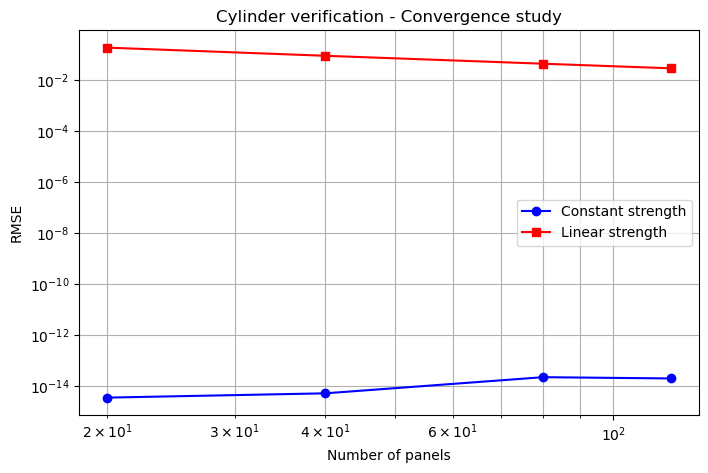

In [7]:

# Convergence study
panel_numbers = [20, 40, 80, 120]

constant_errors = []
linear_errors = []

alpha = np.radians(5)

for N in panel_numbers:

    result0 = cylinder_test_constant(N, alpha)
    result1 = cylinder_test_linear(N, alpha)

    constant_errors.append(result0[-1])
    linear_errors.append(result1[-1])

    print(
        "Panels:", N,
        "| Constant RMSE:", fmt(result0[-1]),
        "| Linear RMSE:", fmt(result1[-1])
    )


# Plot convergence
plt.figure(figsize=(8, 5))

plt.loglog(
    panel_numbers, constant_errors,
    'bo-', label='Constant strength'
)

plt.loglog(
    panel_numbers, linear_errors,
    'rs-', label='Linear strength'
)

plt.xlabel("Number of panels")
plt.ylabel("RMSE")
plt.title("Cylinder verification - Convergence study")
plt.legend()
plt.grid(True, which='both')
plt.show()


Panels: 20 | Constant RMSE: 0 | Linear RMSE: 0.1859
Panels: 40 | Constant RMSE: 0 | Linear RMSE: 0.0891
Panels: 80 | Constant RMSE: 0 | Linear RMSE: 0.0435
Panels: 120 | Constant RMSE: 0 | Linear RMSE: 0.0288


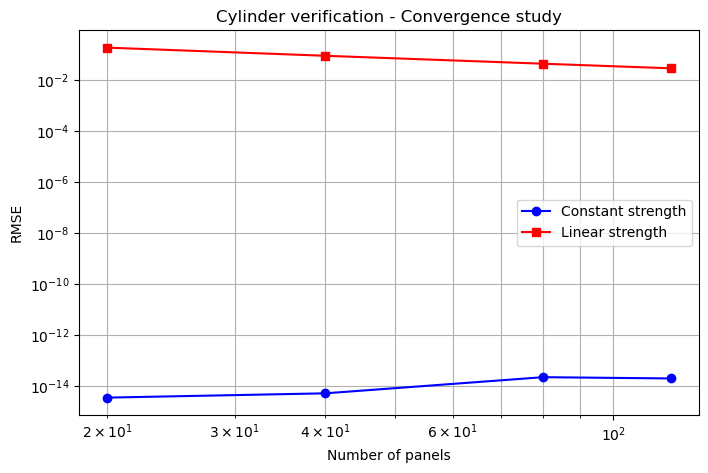

In [8]:

# Convergence study for circular cylinder

panel_numbers = [20, 40, 80, 120]

constant_errors = []
linear_errors = []

alpha = np.radians(5)

for N in panel_numbers:

    # Constant-strength method
    result0 = cylinder_test_constant(N, alpha)
    constant_errors.append(result0[-1])

    # Linear-strength method
    result1 = cylinder_test_linear(N, alpha)
    linear_errors.append(result1[-1])

    print(
        "Panels:", N,
        "| Constant RMSE:", fmt(result0[-1]),
        "| Linear RMSE:", fmt(result1[-1])
    )


# Plot convergence results
plt.figure(figsize=(8, 5))

plt.loglog(
    panel_numbers,
    constant_errors,
    'bo-',
    label='Constant strength'
)

plt.loglog(
    panel_numbers,
    linear_errors,
    'rs-',
    label='Linear strength'
)

plt.xlabel("Number of panels")
plt.ylabel("RMSE")
plt.title("Cylinder verification - Convergence study")
plt.legend()
plt.grid(True, which='both')
plt.show()


NACA 0012
-------------------------
Constant-strength Cl: 0.5957
Linear-strength Cl: 0.5867
Constant-strength normal error: 0.0002
Linear-strength normal error: 0

NACA 2412
-------------------------
Constant-strength Cl: 0.8371
Linear-strength Cl: 0.8376
Constant-strength normal error: 0.0002
Linear-strength normal error: 0



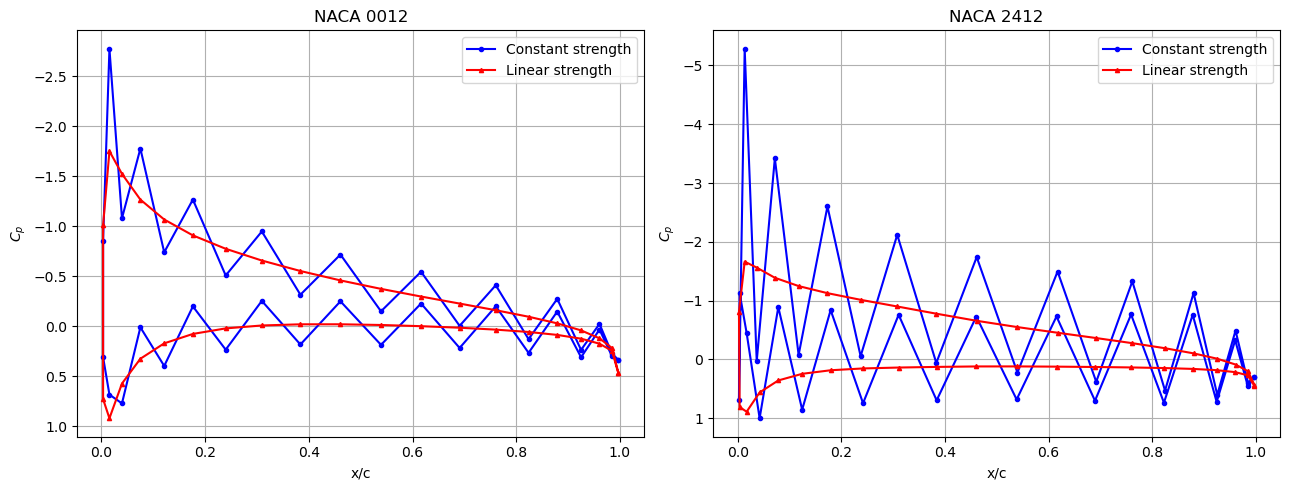

In [9]:

# Compare NACA 0012 and NACA 2412

N = 40
alpha = np.radians(5)

airfoils = ['0012', '2412']

results = {}

for name in airfoils:

    XB, YB = naca4_boundary_points(name, N, spacing='cosine')

    XC, YC, S, phi = panel_geometry(XB, YB)

    # Constant-strength solution
    gamma0, Vt0, Cp0, Cl0, error0 = vortex_panel_method_0(
        XB, YB, alpha
    )

    # Linear-strength solution
    gamma1, Vt1, Cp1, Cl1, error1 = vortex_panel_method_1(
        XB, YB, alpha
    )

    results[name] = {
        'XC': XC,
        'Cp_constant': Cp0,
        'Cp_linear': Cp1,
        'Cl_constant': Cl0,
        'Cl_linear': Cl1
    }

    print("NACA", name)
    print("-------------------------")
    print("Constant-strength Cl:", fmt(Cl0))
    print("Linear-strength Cl:", fmt(Cl1))
    print("Constant-strength normal error:", fmt(error0))
    print("Linear-strength normal error:", fmt(error1))
    print()


# Plot pressure distributions
fig, ax = plt.subplots(1, 2, figsize=(13, 5))

for i, name in enumerate(airfoils):

    ax[i].plot(
        results[name]['XC'],
        results[name]['Cp_constant'],
        'bo-', markersize=3,
        label='Constant strength'
    )

    ax[i].plot(
        results[name]['XC'],
        results[name]['Cp_linear'],
        'r^-', markersize=3,
        label='Linear strength'
    )

    ax[i].invert_yaxis()
    ax[i].set_xlabel("x/c")
    ax[i].set_ylabel("$C_p$")
    ax[i].set_title("NACA " + name)
    ax[i].legend()
    ax[i].grid()

plt.tight_layout()
plt.show()


Effect of panel number
----------------------
Panels: 20
NACA 0012 constant: 0.5641
NACA 0012 linear: 0.5728
NACA 2412 constant: 0.8212
NACA 2412 linear: 0.8156

Panels: 40
NACA 0012 constant: 0.5957
NACA 0012 linear: 0.5867
NACA 2412 constant: 0.8371
NACA 2412 linear: 0.8376

Panels: 80
NACA 0012 constant: 0.597
NACA 0012 linear: 0.5939
NACA 2412 constant: 0.8567
NACA 2412 linear: 0.8483



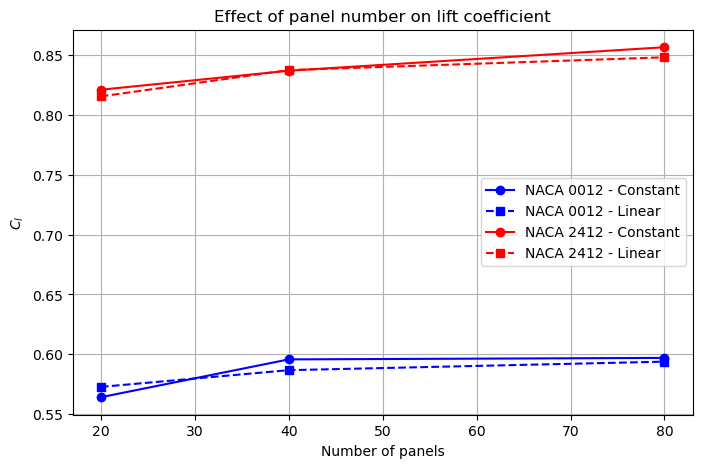

In [10]:

# Study the effect of panel number

panel_numbers = [20, 40, 80]
alpha = np.radians(5)

Cl_constant_0012 = []
Cl_linear_0012 = []

Cl_constant_2412 = []
Cl_linear_2412 = []

for N in panel_numbers:

    # NACA 0012
    XB, YB = naca4_boundary_points('0012', N, spacing='cosine')

    result0 = vortex_panel_method_0(XB, YB, alpha)
    result1 = vortex_panel_method_1(XB, YB, alpha)

    Cl_constant_0012.append(result0[3])
    Cl_linear_0012.append(result1[3])

    # NACA 2412
    XB, YB = naca4_boundary_points('2412', N, spacing='cosine')

    result0 = vortex_panel_method_0(XB, YB, alpha)
    result1 = vortex_panel_method_1(XB, YB, alpha)

    Cl_constant_2412.append(result0[3])
    Cl_linear_2412.append(result1[3])


print("Effect of panel number")
print("----------------------")

for i, N in enumerate(panel_numbers):

    print("Panels:", N)
    print("NACA 0012 constant:", fmt(Cl_constant_0012[i]))
    print("NACA 0012 linear:", fmt(Cl_linear_0012[i]))
    print("NACA 2412 constant:", fmt(Cl_constant_2412[i]))
    print("NACA 2412 linear:", fmt(Cl_linear_2412[i]))
    print()


# Plot lift coefficient against panel number
plt.figure(figsize=(8, 5))

plt.plot(
    panel_numbers, Cl_constant_0012,
    'bo-', label='NACA 0012 - Constant'
)

plt.plot(
    panel_numbers, Cl_linear_0012,
    'bs--', label='NACA 0012 - Linear'
)

plt.plot(
    panel_numbers, Cl_constant_2412,
    'ro-', label='NACA 2412 - Constant'
)

plt.plot(
    panel_numbers, Cl_linear_2412,
    'rs--', label='NACA 2412 - Linear'
)

plt.xlabel("Number of panels")
plt.ylabel("$C_l$")
plt.title("Effect of panel number on lift coefficient")
plt.legend()
plt.grid()
plt.show()


Panel spacing: uniform
Constant-strength Cl: 0.8992
Linear-strength Cl: 0.8219

Panel spacing: cosine
Constant-strength Cl: 0.8371
Linear-strength Cl: 0.8376



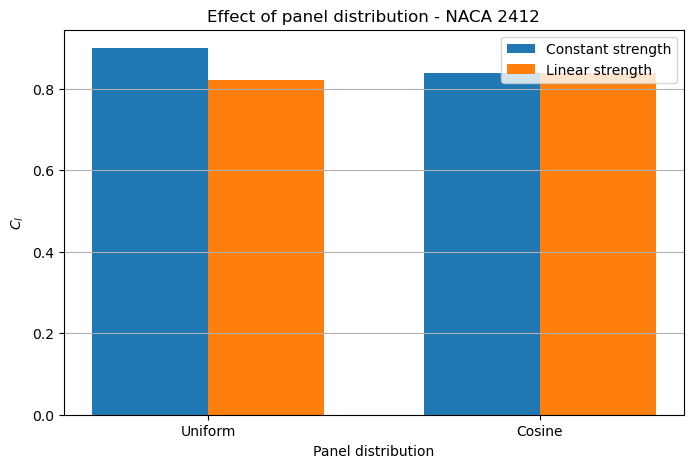

In [11]:

# Compare uniform and cosine panel spacing

N = 40
alpha = np.radians(5)

spacing_types = ['uniform', 'cosine']

spacing_results = {}

for spacing in spacing_types:

    XB, YB = naca4_boundary_points(
        '2412', N, spacing=spacing
    )

    result0 = vortex_panel_method_0(XB, YB, alpha)
    result1 = vortex_panel_method_1(XB, YB, alpha)

    spacing_results[spacing] = {
        'Cl_constant': result0[3],
        'Cl_linear': result1[3]
    }

    print("Panel spacing:", spacing)
    print("Constant-strength Cl:", fmt(result0[3]))
    print("Linear-strength Cl:", fmt(result1[3]))
    print()


# Compare lift coefficients
labels = ['Uniform', 'Cosine']

constant_values = [
    spacing_results['uniform']['Cl_constant'],
    spacing_results['cosine']['Cl_constant']
]

linear_values = [
    spacing_results['uniform']['Cl_linear'],
    spacing_results['cosine']['Cl_linear']
]

x = np.arange(len(labels))
width = 0.35

plt.figure(figsize=(8, 5))

plt.bar(
    x - width/2, constant_values,
    width, label='Constant strength'
)

plt.bar(
    x + width/2, linear_values,
    width, label='Linear strength'
)

plt.xticks(x, labels)
plt.xlabel("Panel distribution")
plt.ylabel("$C_l$")
plt.title("Effect of panel distribution - NACA 2412")
plt.legend()
plt.grid(axis='y')
plt.show()


In [12]:

def aerodynamic_coefficients(XB, YB, Cp, chord=1):

    XC, YC, S, phi = panel_geometry(XB, YB)

    # Outward normal components
    nx = -np.sin(phi)
    ny = np.cos(phi)

    # Pressure force coefficients
    Cd = -np.sum(Cp * nx * S) / chord
    Cl = -np.sum(Cp * ny * S) / chord

    # Moment about quarter-chord
    x_ref = 0.25 * chord
    y_ref = 0

    Cm = -np.sum(
        Cp * (
            (XC - x_ref) * ny -
            (YC - y_ref) * nx
        ) * S
    ) / chord**2

    return Cl, Cd, Cm


# Aerodynamic coefficients for NACA 2412
N = 40
alpha = np.radians(5)

XB, YB = naca4_boundary_points(
    '2412', N, spacing='cosine'
)

# Constant-strength method
gamma0, Vt0, Cp0, Cl0, error0 = vortex_panel_method_0(
    XB, YB, alpha
)

Cl0, Cd0, Cm0 = aerodynamic_coefficients(
    XB, YB, Cp0
)

# Linear-strength method
gamma1, Vt1, Cp1, Cl1, error1 = vortex_panel_method_1(
    XB, YB, alpha
)

Cl1, Cd1, Cm1 = aerodynamic_coefficients(
    XB, YB, Cp1
)

print("Aerodynamic coefficients - NACA 2412")
print("-------------------------------------")
print("Angle of attack: 5 degrees")
print()
print("Constant-strength method")
print("Cl:", fmt(Cl0))
print("Pressure Cd:", fmt(Cd0))
print("Cm at quarter-chord:", fmt(Cm0))
print()
print("Linear-strength method")
print("Cl:", fmt(Cl1))
print("Pressure Cd:", fmt(Cd1))
print("Cm at quarter-chord:", fmt(Cm1))


Aerodynamic coefficients - NACA 2412
-------------------------------------
Angle of attack: 5 degrees

Constant-strength method
Cl: 0.8371
Pressure Cd: -0.1162
Cm at quarter-chord: 0.0645

Linear-strength method
Cl: 0.8376
Pressure Cd: -0.0611
Cm at quarter-chord: 0.0642


Angle: -2 | Constant Cl: 0.016 | Linear Cl: 0.0166
Angle: 0 | Constant Cl: 0.2578 | Linear Cl: 0.2525
Angle: 2 | Constant Cl: 0.4945 | Linear Cl: 0.4879
Angle: 4 | Constant Cl: 0.7247 | Linear Cl: 0.7217
Angle: 6 | Constant Cl: 0.9475 | Linear Cl: 0.9527
Angle: 8 | Constant Cl: 1.1616 | Linear Cl: 1.1798


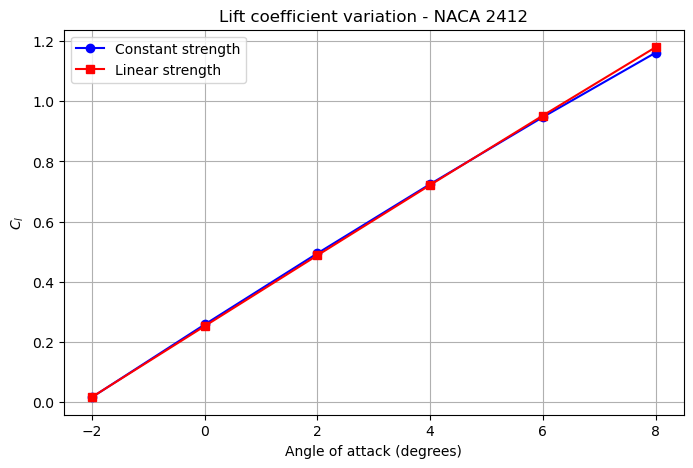

NACA 0012
Constant-strength Cl: 0.5957
Linear-strength Cl: 0.5867

NACA 0015
Constant-strength Cl: 0.6166
Linear-strength Cl: 0.5996

NACA 0018
Constant-strength Cl: 0.6267
Linear-strength Cl: 0.6126



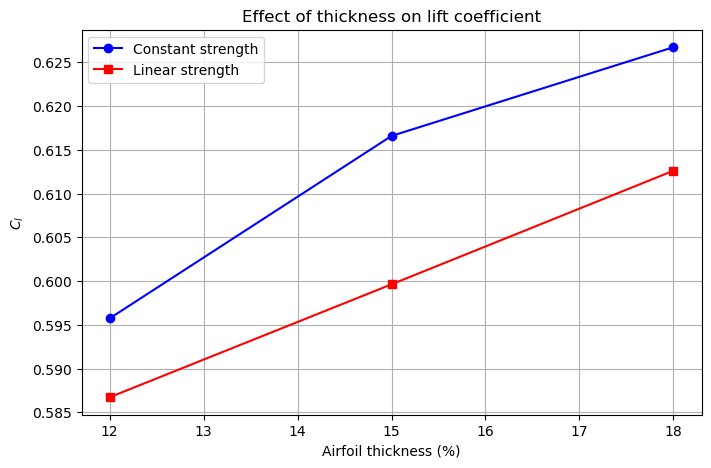

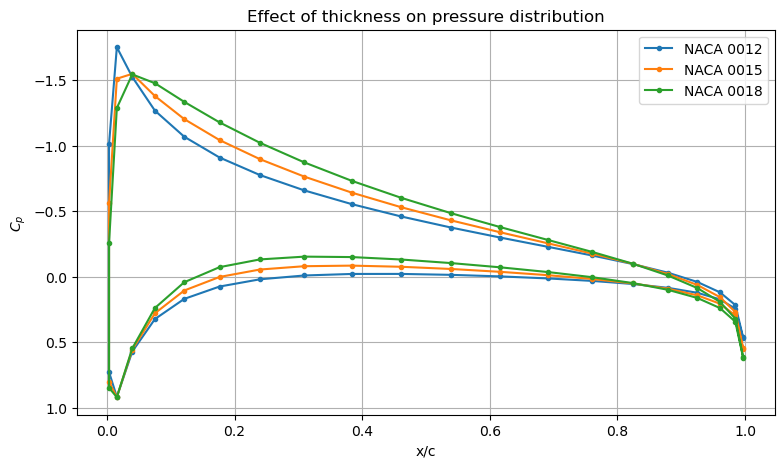

In [13]:

# Lift variation with angle of attack

N = 40
angles = [-2, 0, 2, 4, 6, 8]

Cl_constant = []
Cl_linear = []

for angle in angles:

    alpha = np.radians(angle)

    XB, YB = naca4_boundary_points(
        '2412', N, spacing='cosine'
    )

    result0 = vortex_panel_method_0(XB, YB, alpha)
    result1 = vortex_panel_method_1(XB, YB, alpha)

    Cl_constant.append(result0[3])
    Cl_linear.append(result1[3])

    print(
        "Angle:", angle,
        "| Constant Cl:", fmt(result0[3]),
        "| Linear Cl:", fmt(result1[3])
    )


# Plot lift coefficient against angle of attack
plt.figure(figsize=(8, 5))

plt.plot(
    angles, Cl_constant,
    'bo-', label='Constant strength'
)

plt.plot(
    angles, Cl_linear,
    'rs-', label='Linear strength'
)

plt.xlabel("Angle of attack (degrees)")
plt.ylabel("$C_l$")
plt.title("Lift coefficient variation - NACA 2412")
plt.legend()
plt.grid()
plt.show()


# Effect of airfoil thickness

airfoils = ['0012', '0015', '0018']

thickness = [12, 15, 18]

Cl_constant = []
Cl_linear = []

Cp_constant = {}
Cp_linear = {}

alpha = np.radians(5)
N = 40

for name in airfoils:

    XB, YB = naca4_boundary_points(
        name, N, spacing='cosine'
    )

    result0 = vortex_panel_method_0(XB, YB, alpha)
    result1 = vortex_panel_method_1(XB, YB, alpha)

    Cl_constant.append(result0[3])
    Cl_linear.append(result1[3])

    Cp_constant[name] = result0[2]
    Cp_linear[name] = result1[2]

    print("NACA", name)
    print("Constant-strength Cl:", fmt(result0[3]))
    print("Linear-strength Cl:", fmt(result1[3]))
    print()


# Plot lift coefficient for different thicknesses
plt.figure(figsize=(8, 5))

plt.plot(
    thickness, Cl_constant,
    'bo-', label='Constant strength'
)

plt.plot(
    thickness, Cl_linear,
    'rs-', label='Linear strength'
)

plt.xlabel("Airfoil thickness (%)")
plt.ylabel("$C_l$")
plt.title("Effect of thickness on lift coefficient")
plt.legend()
plt.grid()
plt.show()


# Compare pressure distribution for different thicknesses
XB, YB = naca4_boundary_points(
    '0012', N, spacing='cosine'
)

XC, YC, S, phi = panel_geometry(XB, YB)

plt.figure(figsize=(9, 5))

for name in airfoils:

    plt.plot(
        XC, Cp_linear[name],
        marker='o',
        markersize=3,
        label='NACA ' + name
    )

plt.gca().invert_yaxis()
plt.xlabel("x/c")
plt.ylabel("$C_p$")
plt.title("Effect of thickness on pressure distribution")
plt.legend()
plt.grid()
plt.show()
